# Code example: using FBPINNs and D3M to solve Poisson's equation in 1D

We consider the one-dimensional Poisson boundary value problem:

$$
\frac{d^2 u}{dx^2} = -(40\pi)^2 \sin(40\pi x)
$$
over the domain
$$
\Omega = [0, 1]
$$
with boundary conditions
$$
u(0) = 0, \qquad u(1) = 0
$$
In this case, the exact solution is given by
$$
u(x) = \sin(40\pi x)
$$

In [1]:
# Import relevant libraries and create plot directory

import os
import torch
from torch import nn
import numpy as np

import matplotlib.pyplot as plt
params = {'text.usetex': False, 'mathtext.fontset': 'cm'}
plt.rcParams.update(params)
import matplotlib.colors as mcolors
colors = 10*list(mcolors.TABLEAU_COLORS.values())

os.makedirs("plots", exist_ok=True)

def savefig(filename):
    "Helper function which saves a figure to the plot directory"
    plt.savefig(f"plots/{filename}", bbox_inches="tight", dpi=150, pad_inches=0.02, facecolor="white")

In [2]:
def exact_solution(x):
    '''Defines the analytical solution to the Poisson boundary value problem
               d^2u
    Equation:  ---- = - (40 pi)^2 sin(40 pi x)
               dx^2
    Domain: Omega = [0,1]
    Boundary conditions: u(0) = u(1) = 0
    Exact solution: u(x) = sin(40 pi x)'''
    u = torch.sin(40*torch.pi*x)
    return u
    
class FCN(nn.Module):
    "Defines a standard fully-connected network in PyTorch"
    
    def __init__(self, in_features, out_features, hidden_features, n_hidden_layers):
        """
        Initialises network's parameters.
        
        Parameters
        ----------
        in_features (int) - number of input features
        out_features (int) - number of output features
        hidden_features (int) - number of hidden features
        n_hidden_layers (int) - number of hidden layers
        """
        
        super().__init__()
        activation = nn.Tanh# use tanh activation function
        self.fcs = nn.Sequential(*[
                        nn.Linear(in_features, hidden_features),
                        activation()])
        self.fch = nn.Sequential(*[
                        nn.Sequential(*[
                            nn.Linear(hidden_features, hidden_features),
                            activation()]) for _ in range(n_hidden_layers-1)])
        self.fce = nn.Linear(hidden_features, out_features)

    def forward(self, x):
        x = self.fcs(x)
        x = self.fch(x)
        x = self.fce(x)
        return x

## Training a PINN to solve Poisson equation

PINN step: 1 test loss: 0.9897 learning rate: 0.0100


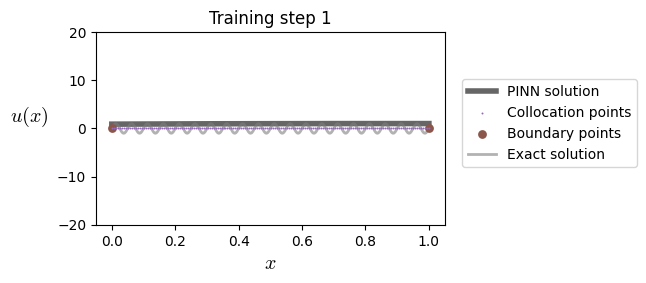

PINN step: 2500 test loss: 0.8350 learning rate: 0.0083


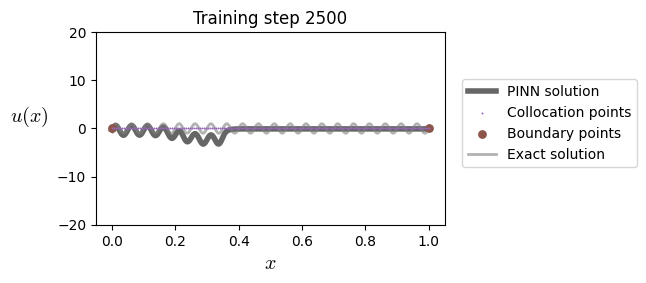

PINN step: 5000 test loss: 2.7059 learning rate: 0.0068


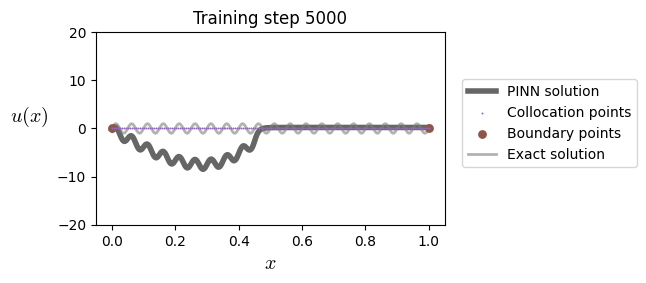

PINN step: 7500 test loss: 3.7798 learning rate: 0.0056


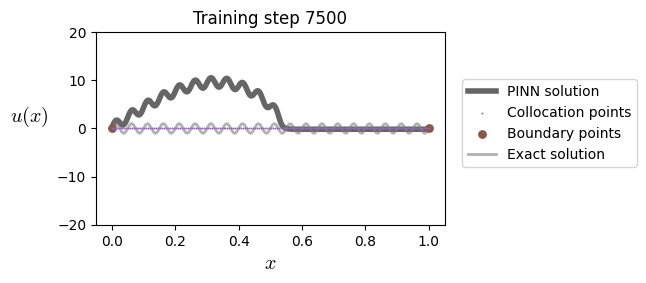

PINN step: 10000 test loss: 3.5579 learning rate: 0.0046


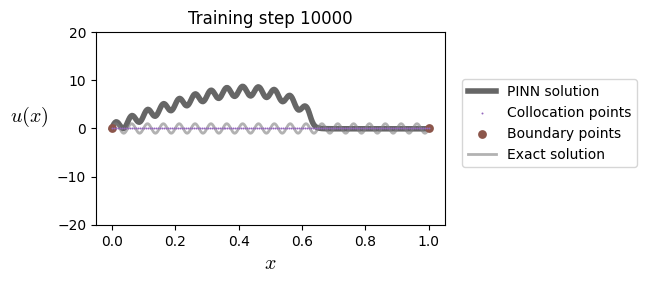

PINN step: 12500 test loss: 6.6102 learning rate: 0.0038


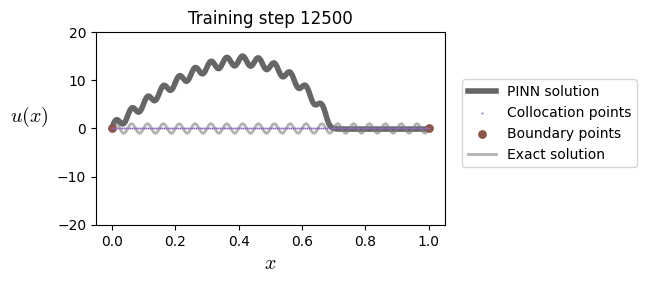

PINN step: 15000 test loss: 4.4955 learning rate: 0.0032


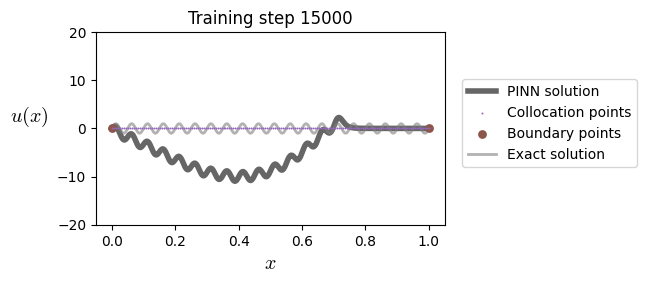

PINN step: 17500 test loss: 6.9803 learning rate: 0.0026


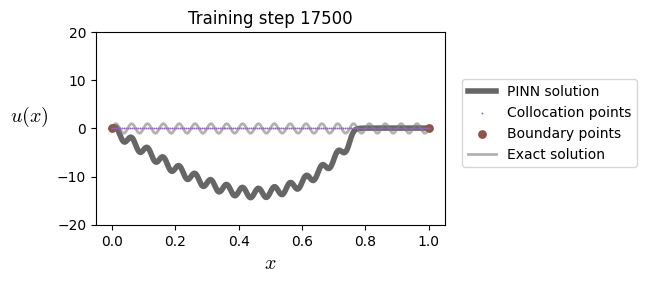

PINN step: 20000 test loss: 5.0390 learning rate: 0.0022


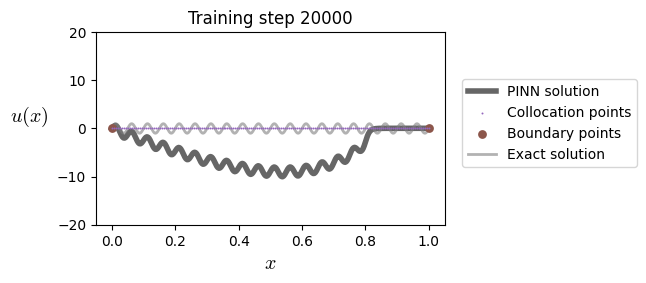

PINN step: 22500 test loss: 2.2827 learning rate: 0.0018


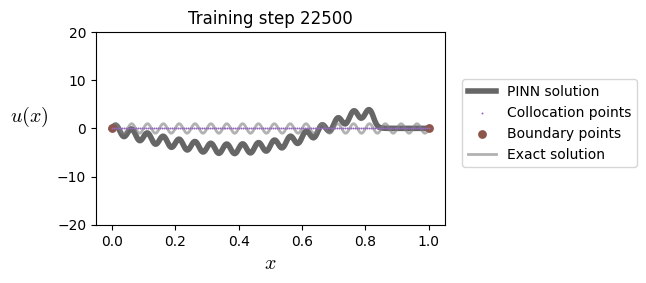

PINN step: 25000 test loss: 1.5722 learning rate: 0.0015


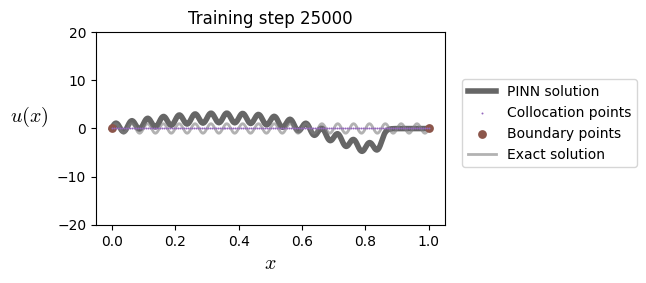

PINN step: 27500 test loss: 1.3415 learning rate: 0.0012


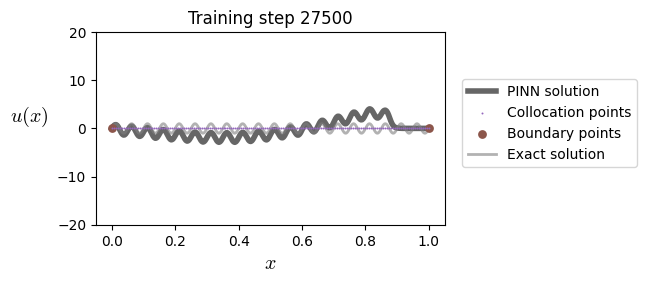

PINN step: 30000 test loss: 9.8570 learning rate: 0.0010


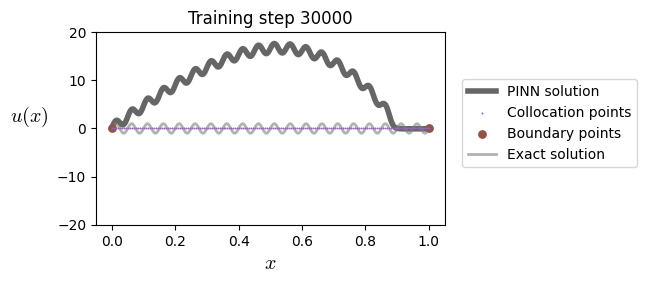

In [3]:
def train_PINN(make_plots=True):
    "Train a PINN on the Poisson boundary value problem"
    
    ## TRAIN MODEL
    
    torch.manual_seed(123)
    
    # define problem
    x_test = torch.linspace(0,1,300).view(-1,1)
    u_exact = exact_solution(x_test)
    
    # define model
    model = FCN(1,1,64,3)
    
    # define boundary points, for the boundary loss
    x_boundary = torch.tensor([0.,1.]).view(2,1).requires_grad_(True)
    
    # define training points over the entire domain, for the physics loss
    x_physics = torch.linspace(0,1,160).view(160,1).requires_grad_(True)
    
    # train the model
    optimiser = torch.optim.Adam(model.parameters(), lr=1e-2)
    N_steps = 30000
    scheduler = torch.optim.lr_scheduler.ExponentialLR(
        optimiser, gamma=(1e-3 / 1e-2) ** (1 / N_steps))
    for i in range(N_steps):
        optimiser.zero_grad()
        
        # compute each term of the PINN loss function
        
        # boundary loss
        u = model(x_boundary)
        loss1 = torch.mean((u - 0)**2)
        
        # physics loss
        u = model(x_physics)
        dudx = torch.autograd.grad(u, x_physics, torch.ones_like(u), create_graph=True)[0]
        d2udx2 = torch.autograd.grad(dudx, x_physics, torch.ones_like(dudx), create_graph=True)[0]
        loss2 = torch.mean((d2udx2 + ((40*torch.pi)**2)*torch.sin(40*torch.pi*x_physics))**2)
        
        # backpropagate joint loss, take optimiser step
        loss = loss1 + 1e-4*loss2
        loss.backward()
        optimiser.step()
        scheduler.step()
        
        # plot the result as training progresses
        if i == 0:
            test_losses = []
        if i == 0 or (i + 1) % 2500 == 0: 
            test_loss = np.abs(model(x_test).detach()-u_exact).mean()
            test_losses.append([i+1, test_loss])
            print(f'PINN step: {i+1} test loss: {test_loss:.4f} learning rate: {optimiser.param_groups[0]["lr"]:.4f}')
            
            if make_plots:
                plt.figure(figsize=(4.5,2.5))
                plt.plot(x_test[:,0], model(x_test)[:,0].detach(), color="black", lw=4, alpha=0.6, label="PINN solution")
                plt.scatter(x_physics.detach()[:,0], 
                            torch.zeros_like(x_physics)[:,0], 
                            s=2, lw=0, color="tab:purple", label="Collocation points", zorder=10)
                plt.scatter(x_boundary.detach()[:,0], 
                            torch.zeros_like(x_boundary)[:,0], 
                            s=40, lw=0, color="tab:brown", label="Boundary points", zorder=9)
                plt.plot(x_test[:,0], u_exact[:,0], lw=2, label="Exact solution", color="tab:grey", alpha=0.6)
                plt.xlabel("$x$", fontsize="x-large")
                plt.ylabel("$u(x)$", fontsize="x-large", rotation=0, labelpad=20)
                plt.title(f"Training step {i+1}")
                plt.legend(loc=(1.05,0.3))
                plt.ylim(-20,20)
                plt.savefig(f"plots/PINN-step-{i+1}.pdf", bbox_inches="tight", dpi=150, pad_inches=0.02, facecolor="white")
                plt.show()
    test_losses_PINN = np.array(test_losses)
    return test_losses_PINN

test_losses_PINN = train_PINN()

## Training a FBPINN to solve Poisson equation

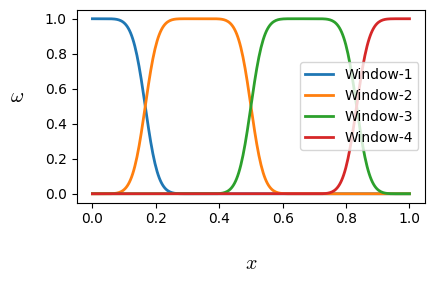

FBPINN step: 1 test loss: 0.6506 learning rate: 0.0100


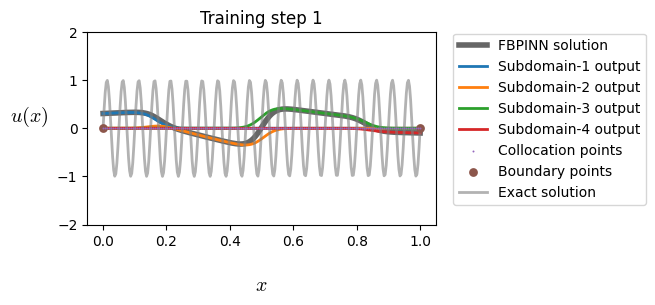

FBPINN step: 2500 test loss: 1.0669 learning rate: 0.0083


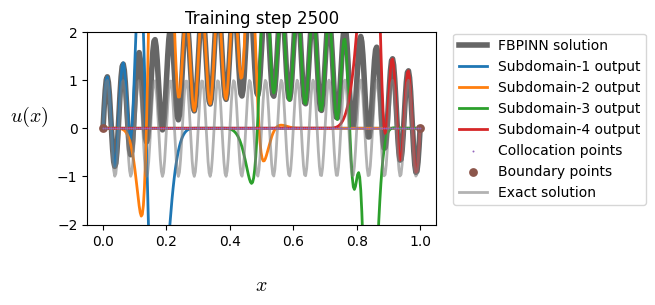

FBPINN step: 5000 test loss: 0.0388 learning rate: 0.0068


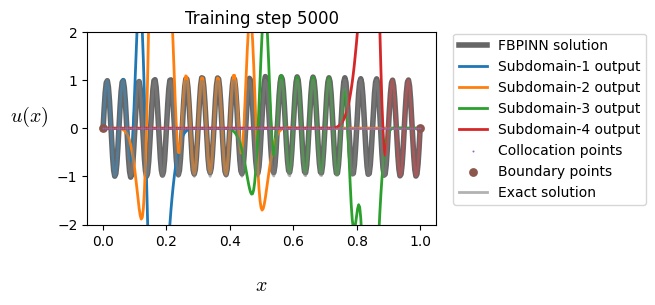

FBPINN step: 7500 test loss: 0.0312 learning rate: 0.0056


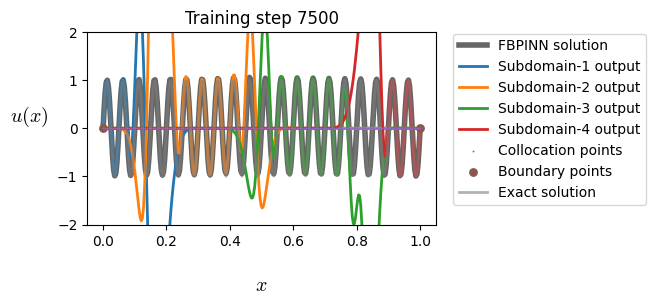

FBPINN step: 10000 test loss: 0.0191 learning rate: 0.0046


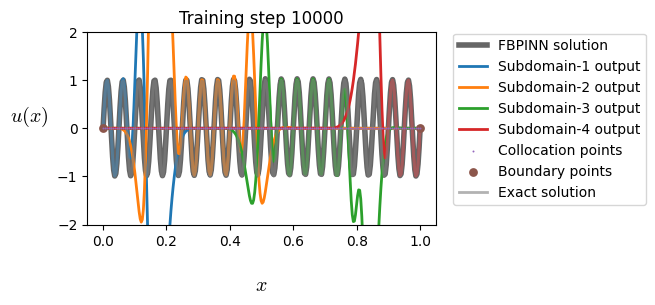

FBPINN step: 12500 test loss: 0.0118 learning rate: 0.0038


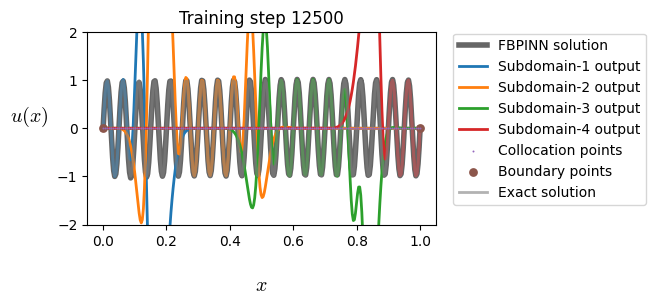

FBPINN step: 15000 test loss: 0.0053 learning rate: 0.0032


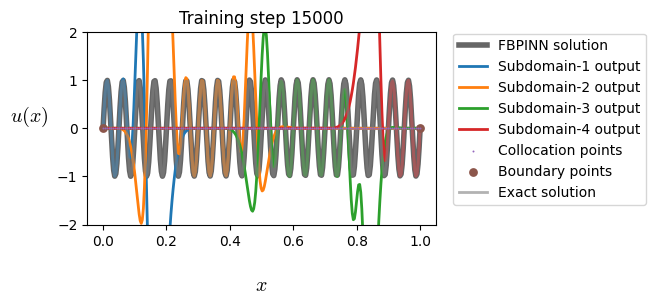

FBPINN step: 17500 test loss: 0.0035 learning rate: 0.0026


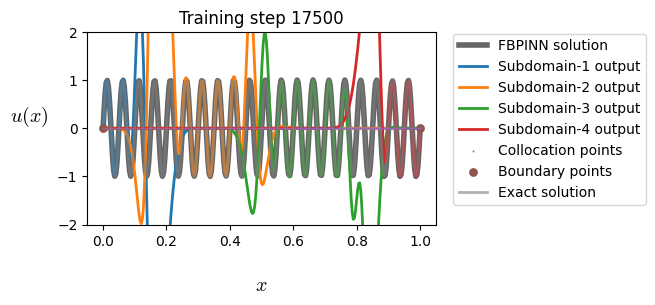

FBPINN step: 20000 test loss: 0.0025 learning rate: 0.0022


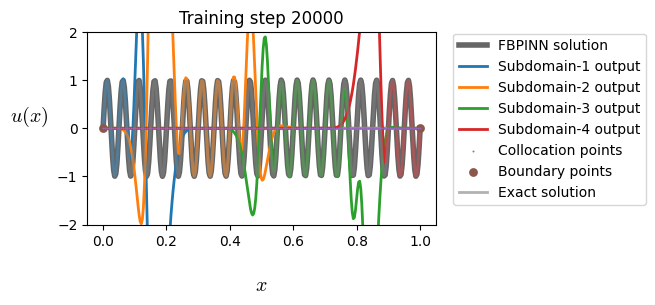

FBPINN step: 22500 test loss: 0.0016 learning rate: 0.0018


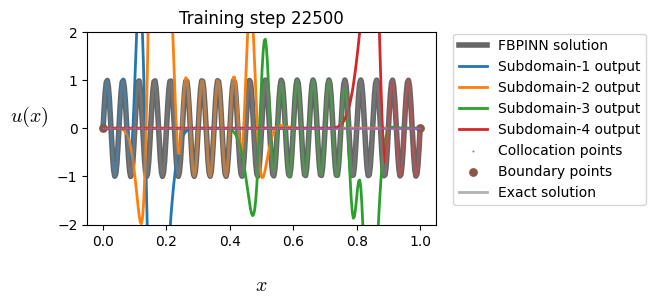

FBPINN step: 25000 test loss: 0.0015 learning rate: 0.0015


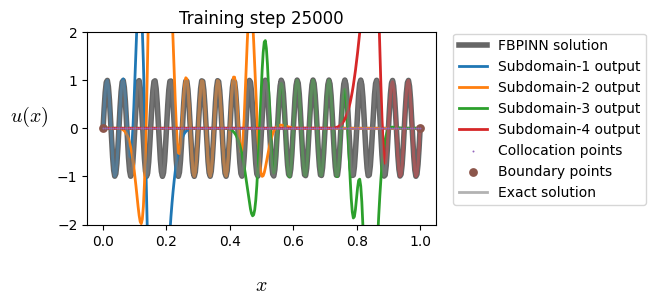

FBPINN step: 27500 test loss: 0.0012 learning rate: 0.0012


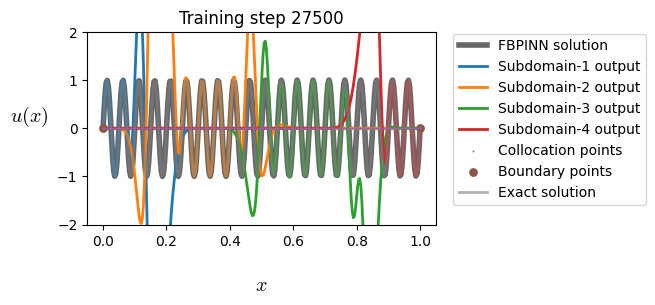

FBPINN step: 30000 test loss: 0.0011 learning rate: 0.0010


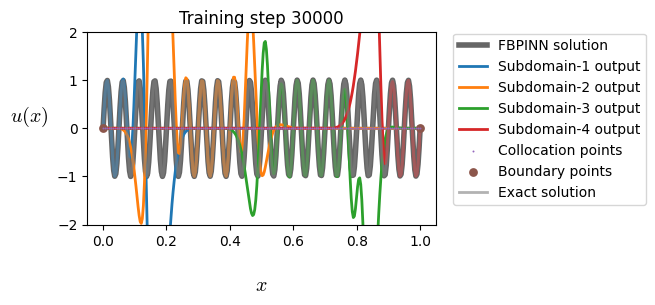

In [4]:
class FBPINN(nn.Module):
    "Defines a finite-basis physics-informed neural network"
    
    def __init__(self, subdomain_edges, subdomain_hidden_features, subdomain_hidden_layers):
        """
        Initialises a (1D) FBPINN.
        
        Parameters
        ----------
        subdomain_edges ((J,2) array) - contains edges (xmin, xmax) of the J subdomains
        subdomain_hidden_features (int) - number of hidden features in each subdomain network
        subdomain_hidden_layers (int) - number of hidden layers in each subdomain network
        """
        
        super().__init__()
        
        self.subdomain_edges = subdomain_edges
        self.J = self.subdomain_edges.shape[0]# number of subdomains
        
        # create subdomain networks
        self.subdomain_networks = nn.ModuleList([FCN(1,1,
                                                     subdomain_hidden_features, 
                                                     subdomain_hidden_layers)
                                                 for _ in range(self.J)])
    
    def window(self, x, xmin, xmax):
        """
        Computes the window function for a subdomain.
        
        Parameters
        ----------
        x ((batch_size, 1) array) - batch of coordinates
        xmin (float) - left edge of subdomain
        xmax (float) - right edge of subdomain
        """

        # Use a cosine-squared window
        mu, sd = (xmin+xmax)/2, (xmax-xmin)/2
        x = (x - mu) / sd
        x = torch.clamp(x, -1.0, 1.0)
        w = ((1 + torch.cos(torch.pi * x)) / 2) ** 2
        return w

    def forward(self, x):
        """
        Computes the output of the FBPINN.
        
        Parameters
        ----------
        x ((batch_size, 1) array) - batch of coordinates
        
        Returns
        -------
        u ((batch_size, 1) array) - solution at x locations
        subdomain_outputs ((J, batch_size, 1) array) - output of each subdomain network at x locations
        window_outputs ((J, batch_size, 1) array) - window value of each subdomain at x locations
        """
        
        # compute outputs of all subdomain networks
        subdomain_outputs = []
        window_outputs = []
        for j in range(self.J):# for each subdomain
            
            # get edges of subdomain
            xmin, xmax = self.subdomain_edges[j]
            
            # normalise the input coordinate over the subdomain
            mu, sd = (xmin+xmax)/2, (xmax-xmin)/2
            x_normalised = (x-mu)/sd
            
            # compute output of subdomain network, and value of window function
            u = self.subdomain_networks[j](x_normalised)# shape (batch_size, 1)
            w = self.window(x, xmin, xmax)# shape (batch_size, 1)
            subdomain_outputs.append(u)
            window_outputs.append(w)
            
        # apply a partition of unity to the window outputs
        window_outputs = torch.stack(window_outputs, axis=0)# shape (J, batch_size, 1)
        window_outputs = window_outputs / window_outputs.sum(axis=0, keepdim=True)# shape (J, batch_size, 1)
        
        # multiply subdomain outputs by window
        subdomain_outputs = torch.stack(subdomain_outputs, axis=0)# shape (J, batch_size, 1)
        subdomain_outputs = subdomain_outputs * window_outputs
        
        # sum all subdomain ouputs together to get final solution
        u = (subdomain_outputs).sum(axis=0)# (batch_size, 1)
        return u, subdomain_outputs, window_outputs
    
    def plot_solution(self, x, plot_window=False):
        """
        Make a pretty plot of the FBPINN solution.
        
        Parameters
        ----------
        x ((batch_size, 1) array) - batch of coordinates
        plot_window (bool) - whether to plot the window functions instead
        """
        
        u, subdomain_outputs, window_outputs = self(x)
        
        plt.figure(figsize=(4.5,2.5))
        if not plot_window:
            plt.plot(x[:,0], u[:,0].detach(), color="black", lw=4, alpha=0.6, label="FBPINN solution")
        for j in range(self.J):
            if plot_window:
                plt.plot(x[:,0], window_outputs[j,:,0].detach(), color=colors[j], lw=2, label=f"Window-{j+1}")
            else:
                plt.plot(x[:,0], subdomain_outputs[j,:,0].detach(), color=colors[j], lw=2, label=f"Subdomain-{j+1} output")
        plt.legend()
        plt.xlabel("$x$", fontsize="x-large", rotation=0, labelpad=20)
        if plot_window:
            plt.ylabel("$\\omega$", fontsize="x-large", rotation=0, labelpad=20)
        else:
            plt.ylabel("$u(x)$", fontsize="x-large", rotation=0, labelpad=20)


def train_FBPINN(n_subdomains, make_plots=True):
    "Train a FBPINN on the Poisson boundary value problem"
    
    ## TRAIN MODEL
    
    torch.manual_seed(123)
    
    # define problem
    x_test = torch.linspace(0,1,300).view(-1,1)
    u_exact = exact_solution(x_test)
    
    # define model
    subdomain_centers = torch.linspace(0,1,n_subdomains)
    center_spacing = subdomain_centers[1]-subdomain_centers[0]
    subdomain_edges = torch.tensor([[x-(0.9*center_spacing), x+(0.9*center_spacing)] for x in subdomain_centers])
    model = FBPINN(subdomain_edges=subdomain_edges,
                   subdomain_hidden_features=32, 
                   subdomain_hidden_layers=1)
    
    # plot FBPINN window functions
    if make_plots:
        model.plot_solution(x_test, plot_window=True)
        savefig("FBPINN-model.pdf")
        plt.show()
    
    # define boundary points, for the boundary loss
    x_boundary = torch.tensor([0.,1.]).view(2,1).requires_grad_(True)
    
    # define training points over the entire domain, for the physics loss
    x_physics = torch.linspace(0,1,40*n_subdomains).view(40*n_subdomains,1).requires_grad_(True)
    
    # train the model
    optimiser = torch.optim.Adam(model.parameters(), lr=1e-2)
    N_steps = 30000
    scheduler = torch.optim.lr_scheduler.ExponentialLR(
        optimiser, gamma=(1e-3 / 1e-2) ** (1 / N_steps))
    for i in range(N_steps):
        optimiser.zero_grad()
        
        # compute each term of the PINN loss function
        
        # boundary loss
        u = model(x_boundary)[0]
        loss1 = torch.mean((u - 0)**2)
        
        # physics loss
        u = model(x_physics)[0]
        dudx = torch.autograd.grad(u, x_physics, torch.ones_like(u), create_graph=True)[0]
        d2udx2 = torch.autograd.grad(dudx, x_physics, torch.ones_like(dudx), create_graph=True)[0]
        loss2 = torch.mean((d2udx2 + ((40*torch.pi)**2)*torch.sin(40*torch.pi*x_physics))**2)
        
        # backpropagate joint loss, take optimiser step
        loss = loss1 + 1e-4*loss2
        loss.backward()
        optimiser.step()
        scheduler.step()
        
        # plot the result as training progresses
        if i == 0:
            test_losses = []
        if i == 0 or (i + 1) % 2500 == 0: 
            test_loss = np.abs(model(x_test)[0].detach()-u_exact).mean()
            test_losses.append([i+1, test_loss])
            print(f'FBPINN step: {i+1} test loss: {test_loss:.4f} learning rate: {optimiser.param_groups[0]["lr"]:.4f}')
            
            if make_plots:
                model.plot_solution(x_test)
                plt.scatter(x_physics.detach()[:,0], 
                            torch.zeros_like(x_physics)[:,0], 
                            s=2, lw=0, color="tab:purple", label="Collocation points", zorder=10)
                plt.scatter(x_boundary.detach()[:,0], 
                            torch.zeros_like(x_boundary)[:,0], 
                            s=40, lw=0, color="tab:brown", label="Boundary points", zorder=9)
                plt.plot(x_test[:,0], u_exact[:,0], lw=2, label="Exact solution", color="tab:grey", alpha=0.6)
                plt.title(f"Training step {i+1}")
                plt.legend(loc=(1.05,0.1))
                plt.ylim(-2,2)
                plt.savefig(f"plots/FBPINN-step-{i+1}.pdf", bbox_inches="tight", dpi=150, pad_inches=0.02, facecolor="white")
                plt.show()
    test_losses_FBPINN = np.array(test_losses)
    return test_losses_FBPINN

test_losses_FBPINN = train_FBPINN(n_subdomains=4)

## Training a D3M to solve Poisson equation

D3M step: 25 test loss: 0.6601 learning rate: 0.0100


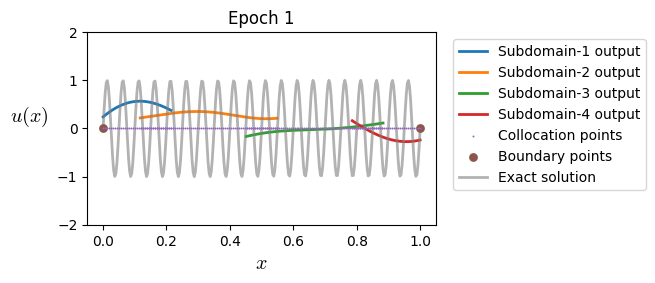

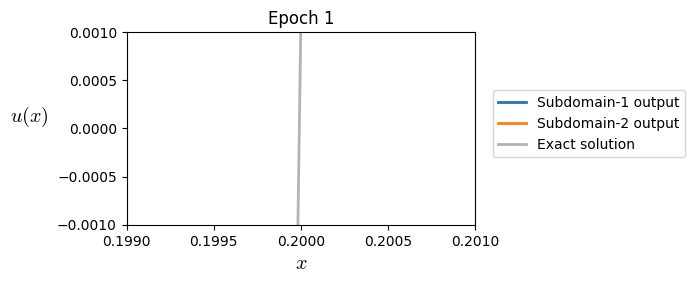

D3M step: 2500 test loss: 10.4106 learning rate: 0.0083


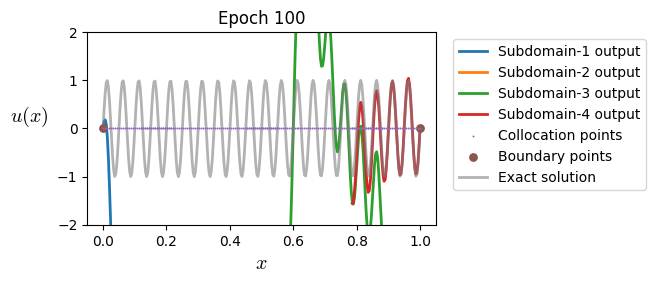

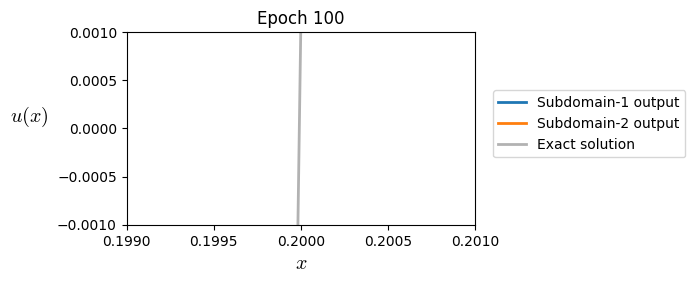

D3M step: 5000 test loss: 11.2885 learning rate: 0.0068


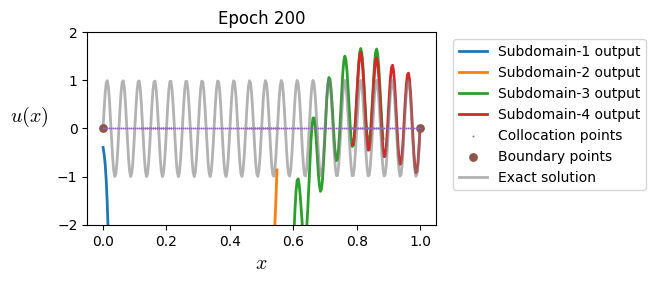

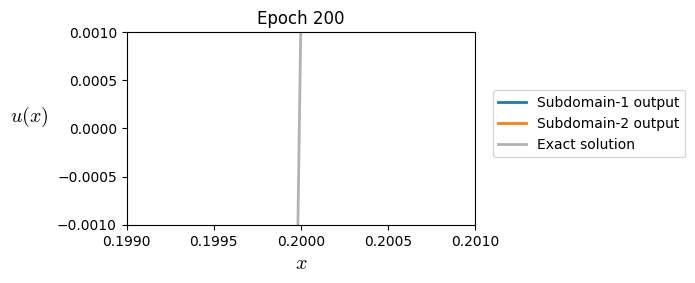

D3M step: 7500 test loss: 1.7417 learning rate: 0.0056


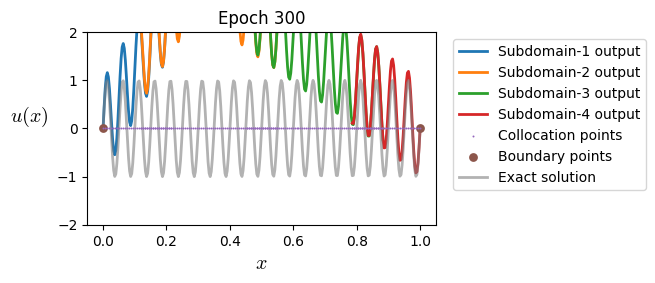

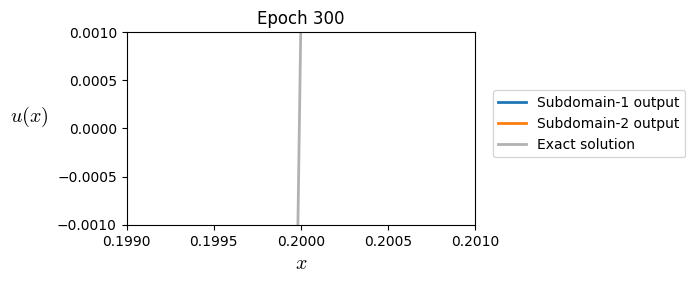

D3M step: 10000 test loss: 0.4320 learning rate: 0.0046


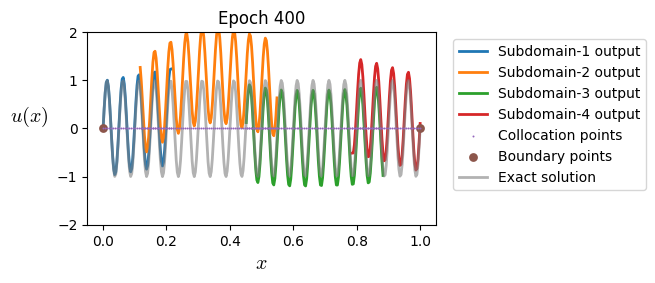

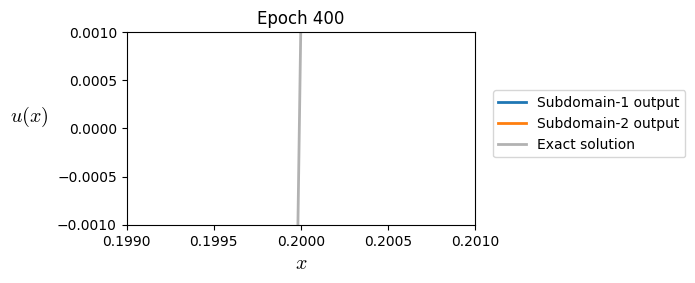

D3M step: 12500 test loss: 0.2182 learning rate: 0.0038


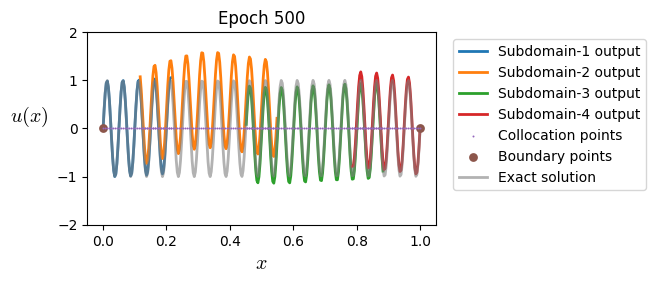

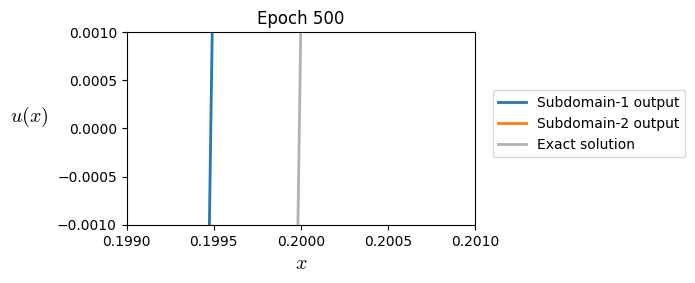

D3M step: 15000 test loss: 0.1325 learning rate: 0.0032


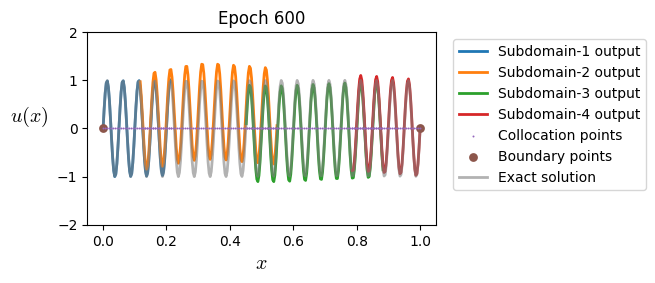

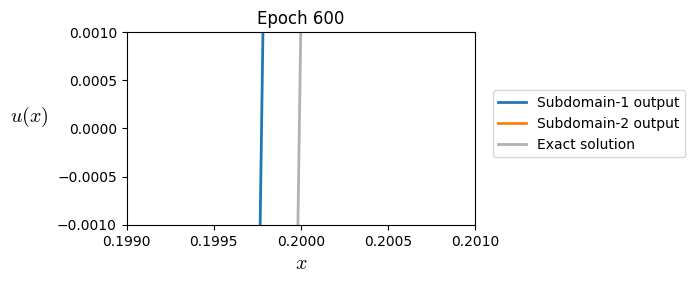

D3M step: 17500 test loss: 0.1134 learning rate: 0.0026


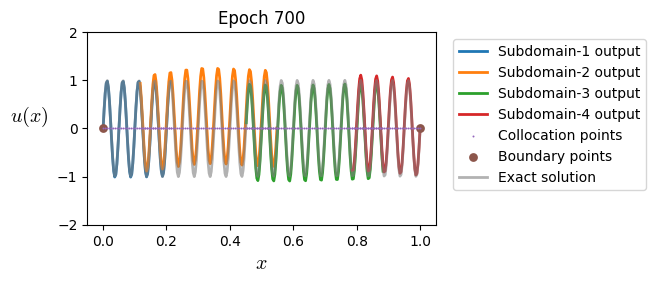

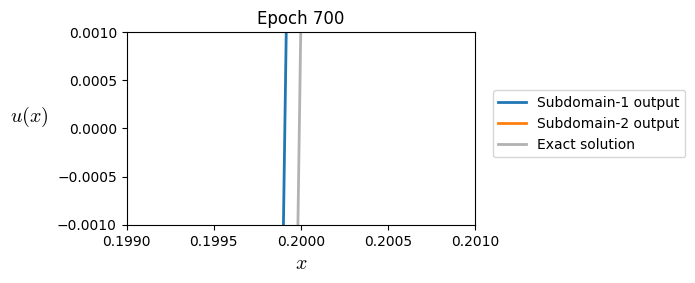

D3M step: 20000 test loss: 0.0955 learning rate: 0.0022


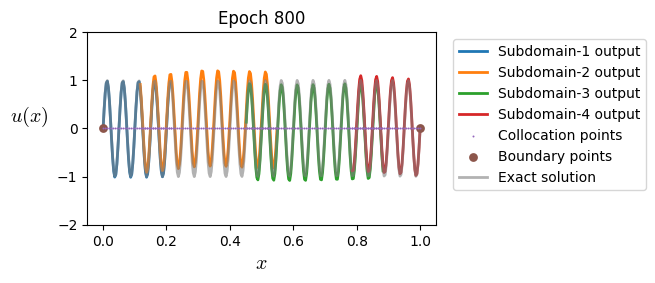

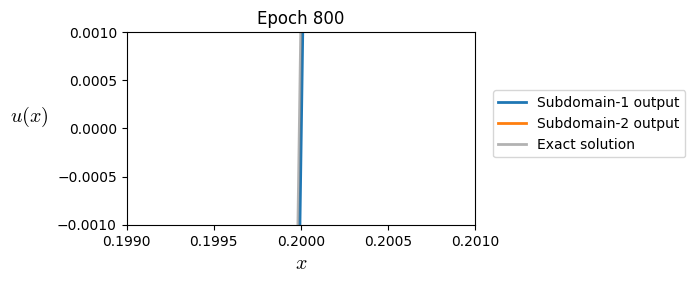

D3M step: 22500 test loss: 0.0764 learning rate: 0.0018


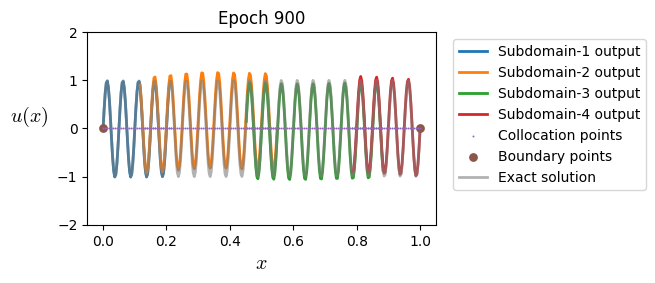

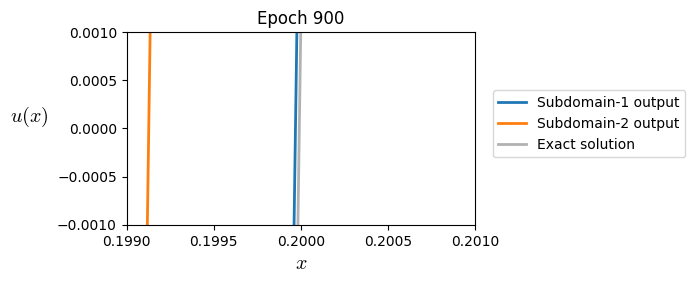

D3M step: 25000 test loss: 0.0635 learning rate: 0.0015


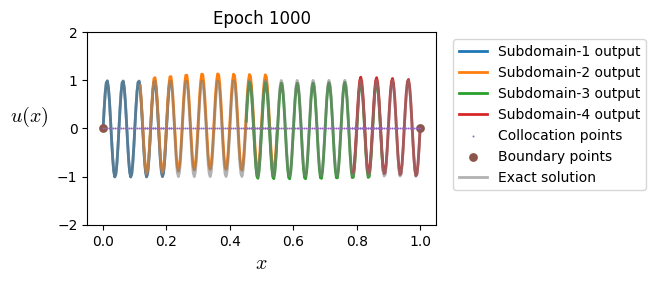

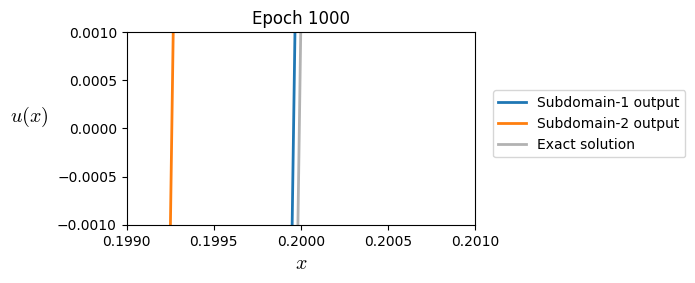

D3M step: 27500 test loss: 0.0533 learning rate: 0.0012


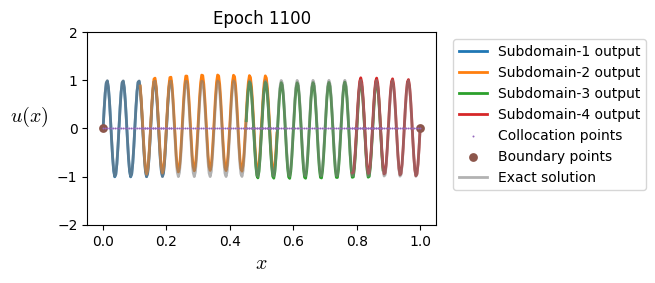

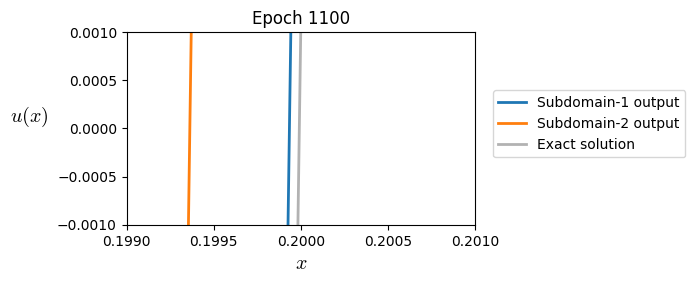

D3M step: 30000 test loss: 0.0438 learning rate: 0.0010


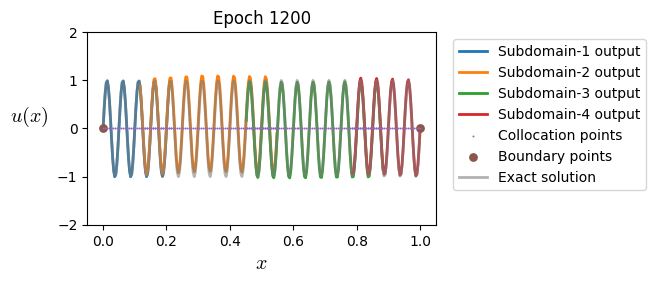

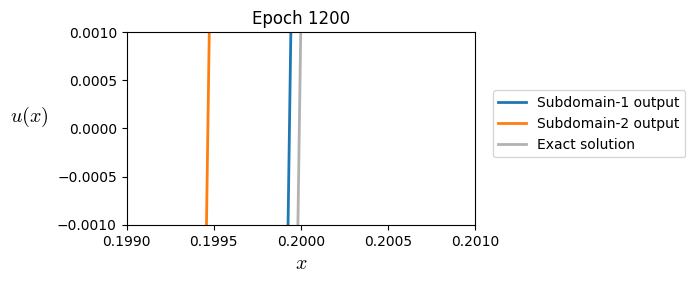

In [5]:
class SubdomainFCN(torch.nn.Module):
    "FCN placed in each subdomain"

    def __init__(self, xmin, xmax, 
                 in_features, out_features, hidden_features, n_hidden_layers):
        """
        Initialises a subdomain network for D3M.
        
        Parameters
        ----------
        (xmin, xmax) - edges of subdomain
        in_features (int) - number of input features
        out_features (int) - number of output features
        hidden_features (int) - number of hidden features
        n_hidden_layers (int) - number of hidden layers
        """
        super().__init__()
        self.xmin, self.xmax = xmin, xmax
        self.fcn = FCN(in_features, out_features, hidden_features, n_hidden_layers)
        
    def forward(self, x):
        """
        Computes subdomain solution at x.
        
        Parameters
        ----------
        x ((batch_size, 1) array) - batch of coordinates
        
        Returns
        -------
        u ((batch_size, 1) array) - solution at x locations
        """
        # normalise the input coordinate over the subdomain
        mu, sd = (self.xmin+self.xmax)/2, (self.xmax-self.xmin)/2
        x_normalised = (x-mu)/sd
        return self.fcn(x_normalised)
        
    def forward_and_grad(self, x):
        """
        Computes subdomain solution and gradient at x.
        
        Parameters
        ----------
        x ((batch_size, 1) array) - batch of coordinates
        
        Returns
        -------
        ug ((2, batch_size, 1) array) - solution and gradient at x locations
        """
        
        u = self.forward(x)
        du = torch.autograd.grad(u, x, torch.ones_like(u), create_graph=True)[0]
        ug = torch.stack([u, du], axis=0)
        return ug
        
    
def train_D3M(n_subdomains, make_plots=True):
    "Train a D3M on the Poisson boundary value problem"
    
    ## TRAIN MODEL
    
    torch.manual_seed(123)
    
    # define problem
    x_test = torch.linspace(0,1,300).view(-1,1)
    u_exact = exact_solution(x_test)
    
    ## define subdomain networks
    subdomain_centers = torch.linspace(0,1,n_subdomains)
    center_spacing = subdomain_centers[1]-subdomain_centers[0]
    subdomain_edges = torch.tensor([[x-(0.65*center_spacing), x+(0.65*center_spacing)] for x in subdomain_centers])
    J = subdomain_edges.shape[0]# number of subdomains
    # defines which subdomains intersect with each subdomain
    subdomain_edge_conditions = [[None if j==0 else j-1, None if j==(J-1) else j+1] for j in range(J)]
    models = [SubdomainFCN(subdomain_edges[j,0],subdomain_edges[j,1],1,1,32,1) for j in range(J)]# create subdomain networks
    
    # define boundary points, for the boundary loss
    x_boundary = torch.tensor([0.,1.]).view(2,1).requires_grad_(True)
    
    # define training points over the entire domain, for the physics loss
    x_physics = torch.linspace(0,1,40*n_subdomains).view(40*n_subdomains,1)
    # define training points for each subdomain, for the physics loss
    subdomain_x_physics = [torch.stack([x for x in x_physics if (x>=xmin and x<=xmax)]).requires_grad_(True)
                           for xmin,xmax in subdomain_edges]
    
    # define test points for each subdomain, for plotting
    subdomain_x_test = [torch.stack([x for x in x_test if (x>=xmin and x<=xmax)])
                           for xmin,xmax in subdomain_edges]
    
    # train the models
    optimisers = [torch.optim.Adam(model.parameters(), lr=1e-2) for model in models]
    N_steps = 30000
    schedulers = [torch.optim.lr_scheduler.ExponentialLR(
        optimiser, gamma=(1e-3 / 1e-2) ** (1 / N_steps)) for optimiser in optimisers]
    training_steps_per_epoch = 25
    for e in range(N_steps//training_steps_per_epoch):
        
        # get edge values and gradients from neighbouring subdomains, for each subdomain
        subdomain_edge_values = []
        for j,(jmin, jmax) in enumerate(subdomain_edge_conditions):# for each subdomain
            ugmin, ugmax = None, None
            if jmin is not None:# get left edge value and gradient from neighbouring subdomain
                xmin = subdomain_edges[j][0:1]
                ugmin = models[jmin].forward_and_grad(xmin.requires_grad_(True).view(-1,1)).detach()
            if jmax is not None:# get right edge value and gradient from neighbouring subdomain
                xmax = subdomain_edges[j][1:2]
                ugmax = models[jmax].forward_and_grad(xmax.requires_grad_(True).view(-1,1)).detach()
            subdomain_edge_values.append([ugmin, ugmax])
        
        # train each subdomain independently (this loop can be parallelised over subdomains)
        for j in range(J):
            for _ in range(training_steps_per_epoch):
                
                optimiser, scheduler = optimisers[j], schedulers[j]
                model = models[j]
                x_physics = subdomain_x_physics[j]
                x_edge = subdomain_edges[j]
                ugmin, ugmax = subdomain_edge_values[j]
                
                optimiser.zero_grad()
                
                # compute each term of the loss function
                
                # boundary loss
                if j==0:
                    u = model(x_boundary[0])
                    loss1 = torch.mean((u - 0)**2)
                elif j==(J-1):
                    u = model(x_boundary[1])
                    loss1 = torch.mean((u - 0)**2)
                else:
                    loss1 = 0.
                                
                # physics loss
                u = model(x_physics)
                dudx = torch.autograd.grad(u, x_physics, torch.ones_like(u), create_graph=True)[0]
                d2udx2 = torch.autograd.grad(dudx, x_physics, torch.ones_like(dudx), create_graph=True)[0]
                loss2 = torch.mean((d2udx2 + ((40*torch.pi)**2)*torch.sin(40*torch.pi*x_physics))**2)
                
                # subdomain interface loss
                ug = model.forward_and_grad(x_edge.view(-1,1).requires_grad_(True))
                loss3, loss4 = 0., 0.
                if ugmin is not None:
                    loss3 += (ug[0,0,0]-ugmin[0,0])**2
                    loss4 += (ug[1,0,0]-ugmin[1,0])**2
                if ugmax is not None:
                    loss3 += (ug[0,1,0]-ugmax[0,0])**2
                    loss4 += (ug[1,1,0]-ugmax[1,0])**2
        
                # backpropagate joint loss, take optimiser step
                loss = loss1 + 1e-4*loss2 + loss3 + 1e-3*loss4
                loss.backward()
                optimiser.step()
                scheduler.step()
        
        # plot the result as training progresses
        if e == 0:
            test_losses = []
        if e == 0 or (e + 1) % (2500//training_steps_per_epoch) == 0: 
            l_, c_ = 0,0
            for j,model in enumerate(models):
                x_testj = subdomain_x_test[j]
                u_testj = model(subdomain_x_test[j])
                l_ += np.abs(u_testj.detach()-exact_solution(x_testj)).sum()
                c_ += u_testj.shape[0]
            test_loss = l_/c_
            test_losses.append([(e+1)*training_steps_per_epoch, test_loss])
            print(f'D3M step: {(e+1)*training_steps_per_epoch} test loss: {test_loss:.4f} learning rate: {optimiser.param_groups[0]["lr"]:.4f}')

            if make_plots:
                plt.figure(figsize=(4.5,2.5))
                for j,model in enumerate(models):
                    plt.plot(subdomain_x_test[j][:,0], model(subdomain_x_test[j]).detach()[:,0], lw=2, label=f"Subdomain-{j+1} output")
                    plt.scatter(subdomain_x_physics[j].detach()[:,0], 
                                torch.zeros_like(subdomain_x_physics[j])[:,0], 
                                s=2, lw=0, color="tab:purple", label="Collocation points" if j==J-1 else None, zorder=10)
                plt.scatter(x_boundary.detach()[:,0], 
                            torch.zeros_like(x_boundary)[:,0], s=40, lw=0, color="tab:brown", label="Boundary points", zorder=9)
                plt.plot(x_test[:,0], u_exact[:,0], lw=2, label="Exact solution", color="tab:grey", alpha=0.6)
                plt.xlabel("$x$", fontsize="x-large")
                plt.ylabel("$u(x)$", fontsize="x-large", rotation=0, labelpad=20)
                plt.title(f"Epoch {e+1}")
                plt.legend(loc=(1.05,0.18))
                plt.ylim(-2,2)
                savefig(f"D3M-epoch-{e+1}.pdf")
                plt.show()
        
                # zoom plot
                plt.figure(figsize=(4.5,2.5))
                for j,model in enumerate(models[:2]):
                    plt.plot(subdomain_x_test[j][:,0], model(subdomain_x_test[j]).detach()[:,0], lw=2, label=f"Subdomain-{j+1} output")
                plt.plot(x_test[:,0], u_exact[:,0], lw=2, label="Exact solution", color="tab:grey", alpha=0.6)
                plt.xlabel("$x$", fontsize="x-large")
                plt.ylabel("$u(x)$", fontsize="x-large", rotation=0, labelpad=20)
                plt.title(f"Epoch {e+1}")
                plt.legend(loc=(1.05,0.35))
                zx, zy = 0.2, 0.0
                plt.xlim(zx-0.001,zx+0.001)
                plt.ylim(zy-0.001, zy+0.001)
                savefig(f"D3M-zoom-epoch-{e+1}.pdf")
                plt.show()
            
    test_losses_D3M = np.array(test_losses)
    return test_losses_D3M

test_losses_D3M = train_D3M(n_subdomains=4)

## Comparing the test accuracy of the PINN, FBPINN and D3M

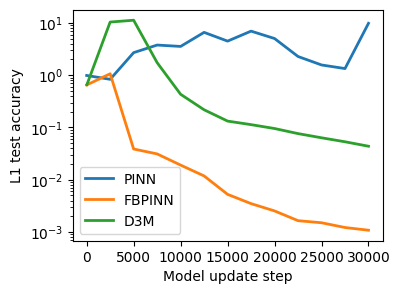

In [6]:
# plot the convergence of the three models
plt.figure(figsize=(4,3))
plt.plot(test_losses_PINN[:,0], test_losses_PINN[:,1], lw=2, label="PINN")
plt.plot(test_losses_FBPINN[:,0], test_losses_FBPINN[:,1], lw=2, label="FBPINN")
plt.plot(test_losses_D3M[:,0], test_losses_D3M[:,1], lw=2, label="D3M")
plt.yscale("log")
plt.ylabel("L1 test accuracy")
plt.xlabel("Model update step")
plt.legend()
savefig("convergence.pdf")
plt.show()

## Strong scaling study for FBPINN and D3M

In this study we carry out a *strong scaling test*: where we solve the same BVP, but increase the model capacity, and see how this affects test accuracy. For the FBPINN and D3M model, we increase model capacity by increasing the number of subdomains.

In [7]:
# train FBPINNs and D3Ms with increasing numbers of subdomains
ns = [2,4,8,16]
test_losses_FBPINNs = [train_FBPINN(n_subdomains, make_plots=False) for n_subdomains in ns]
test_losses_D3Ms = [train_D3M(n_subdomains, make_plots=False) for n_subdomains in ns]

FBPINN step: 1 test loss: 0.6427 learning rate: 0.0100
FBPINN step: 2500 test loss: 4.7080 learning rate: 0.0083
FBPINN step: 5000 test loss: 13.5643 learning rate: 0.0068
FBPINN step: 7500 test loss: 3.3899 learning rate: 0.0056
FBPINN step: 10000 test loss: 18.4113 learning rate: 0.0046
FBPINN step: 12500 test loss: 1.8284 learning rate: 0.0038
FBPINN step: 15000 test loss: 11.8401 learning rate: 0.0032
FBPINN step: 17500 test loss: 21.8715 learning rate: 0.0026
FBPINN step: 20000 test loss: 7.5726 learning rate: 0.0022
FBPINN step: 22500 test loss: 3.1226 learning rate: 0.0018
FBPINN step: 25000 test loss: 3.2853 learning rate: 0.0015
FBPINN step: 27500 test loss: 5.2613 learning rate: 0.0012
FBPINN step: 30000 test loss: 6.7884 learning rate: 0.0010
FBPINN step: 1 test loss: 0.6506 learning rate: 0.0100
FBPINN step: 2500 test loss: 1.0669 learning rate: 0.0083
FBPINN step: 5000 test loss: 0.0388 learning rate: 0.0068
FBPINN step: 7500 test loss: 0.0312 learning rate: 0.0056
FBPINN 

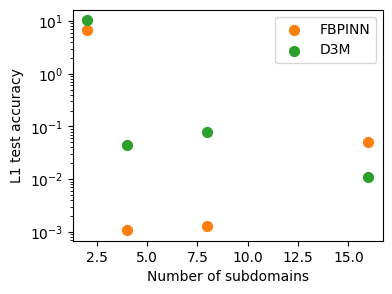

In [8]:
# plot final test accuracy vs number of subdomains, for each method
plt.figure(figsize=(4,3))
for n,test_losses_FBPINN, test_losses_D3M in zip(ns, test_losses_FBPINNs, test_losses_D3Ms):
    plt.scatter(n, test_losses_FBPINN[-1,1], label="FBPINN" if n==ns[0] else None, color="tab:orange", s=50)
    plt.scatter(n, test_losses_D3M[-1,1], label="D3M" if n==ns[0] else None, color="tab:green", s=50)
plt.yscale("log")
plt.ylabel("L1 test accuracy")
plt.xlabel("Number of subdomains")
plt.legend()
savefig("strong-scaling.pdf")
plt.show()